# Temporal rescoring: with vs without

Compares one detector's detections **without** and **with** temporal rescoring (`src/temporal.py`, a simplified Seq-NMS) on the 7 val clips.

**Inputs** (run from `src/` first):
```bash
python infer.py --run ../runs/faster_rcnn/baseline --split valall --scales 720:1280,1080:1920 --val-res test --tag ms
python temporal.py --run ../runs/faster_rcnn/baseline --tag ms    # grid on val -> runs/temporal_results.csv
```
`valall` = detections on every val frame (temporal context); scores are computed only on the labelled frames in `gt_eval_coco.json`.

**This notebook:**
1. the grid-search table written by `temporal.py`, and the best setting;
2. metrics without / with rescoring: overall, per clip, per class and size;
3. a per-frame comparison at an equal number of boxes, and side-by-side frames (left: without, right: with), saved to `outputs/temporal/`.

CPU only; about 3–5 min.

In [1]:
import json
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

SRC = Path.cwd().parent            # this notebook lives in src/experiments/
ROOT = SRC.parent
sys.path.insert(0, str(SRC))
from common.evaluate import evaluate_detections
from temporal import iou_matrix, link_tracks, rescore, with_scores

RUN = ROOT / "runs" / "faster_rcnn" / "baseline"   # any run with inference/<TAG>_valall_dets.json
TAG = "ms"
DATA_ROOT = ROOT / "multiple-object-video-detection-hw-2-ucu-ai-2026"
GT_FILE = ROOT / "data_processed" / "val" / "gt_eval_coco.json"
OUT_DIR = ROOT / "outputs" / "temporal"
OUT_DIR.mkdir(parents=True, exist_ok=True)

GRID_KEYS = ["link_iou", "link_min", "lam", "top_k", "min_len", "single_penalty"]
SHOW_THR = 0.5     # score threshold for the 'without' pictures

## 1. Grid search (from `temporal.py`)

`temporal.py` tried each setting on val and appended one row per setting to `runs/temporal_results.csv`; `setting = none` is the same detections without rescoring.

In [2]:
res = pd.read_csv(ROOT / "runs" / "temporal_results.csv")
res = res[(res["run"] == RUN.name) & (res["tag"] == TAG)]
res = res.drop_duplicates(subset=["setting"] + GRID_KEYS, keep="last")   # latest temporal.py run wins
show = ["setting"] + GRID_KEYS + ["mAP", "AP50", "AP75", "AP_small", "AR"]
base_map = res.loc[res["setting"] == "none", "mAP"].iloc[0]
table = res[show].assign(delta_mAP=res["mAP"] - base_map).sort_values("mAP", ascending=False)
best = table[table["setting"] == "rescore"].iloc[0]
BEST = dict(link_iou=float(best["link_iou"]), link_min=float(best["link_min"]), lam=float(best["lam"]),
            top_k=int(best["top_k"]), min_len=int(best["min_len"]), single_penalty=float(best["single_penalty"]))
print("best setting:", BEST)
table.round(4)

best setting: {'link_iou': 0.5, 'link_min': 0.05, 'lam': 0.7, 'top_k': 15, 'min_len': 3, 'single_penalty': 1.0}


,setting,link_iou,link_min,lam,top_k,min_len,single_penalty,mAP,AP50,AP75,AP_small,AR,delta_mAP
23,rescore,0.5,0.05,0.7,15.0,3.0,1.0,0.2263,0.4684,0.1886,0.1170,0.4612,0.0081
11,rescore,0.3,0.05,0.7,15.0,3.0,1.0,0.2260,0.4692,0.1872,0.1167,0.4612,0.0077
9,rescore,0.3,0.05,0.7,5.0,3.0,1.0,0.2253,0.4683,0.1866,0.1165,0.4612,0.0070
21,rescore,0.5,0.05,0.7,5.0,3.0,1.0,0.2253,0.4667,0.1873,0.1172,0.4612,0.0070
12,rescore,0.3,0.05,0.7,15.0,3.0,0.7,0.2252,0.4679,0.1865,0.1163,0.4612,0.0069
19,rescore,0.5,0.05,0.5,15.0,3.0,1.0,0.2250,0.4666,0.1870,0.1157,0.4612,0.0067
7,rescore,0.3,0.05,0.5,15.0,3.0,1.0,0.2249,0.4675,0.1864,0.1157,0.4612,0.0066
24,rescore,0.5,0.05,0.7,15.0,3.0,0.7,0.2245,0.4648,0.1870,0.1160,0.4612,0.0063
10,rescore,0.3,0.05,0.7,5.0,3.0,0.7,0.2244,0.4664,0.1858,0.1160,0.4612,0.0061
8,rescore,0.3,0.05,0.5,15.0,3.0,0.7,0.2242,0.4665,0.1857,0.1156,0.4612,0.0060


## 2. Metrics without vs with rescoring

The best setting is applied to every val frame. Rescoring changes only scores, never boxes, so recall (AR) cannot change; mAP changes because detections are re-ranked.

In [3]:
gt = json.loads(GT_FILE.read_text())
images = {im["id"]: im for im in gt["images"]}
val = json.loads((RUN / "inference" / f"{TAG}_valall_dets.json").read_text())
print(f"{len(val)} detections on {len({d['image_id'] for d in val})} val frames ({len(images)} labelled)")

tracks = link_tracks(val, BEST["link_iou"], BEST["link_min"])
new_scores = rescore(val, tracks, BEST["lam"], BEST["top_k"], BEST["min_len"], BEST["single_penalty"])
dets = {"without": [d for d in val if d["image_id"] in images],
        "with": [d for d in with_scores(val, new_scores) if d["image_id"] in images]}

metrics = {k: evaluate_detections(GT_FILE, v) for k, v in dets.items()}
overall = pd.DataFrame(metrics).T
overall.loc["delta"] = overall.loc["with"] - overall.loc["without"]
overall[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR"]].round(4)

1209927 detections on 2846 val frames (359 labelled)


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR
without,0.2182,0.4540,0.1808,0.1084,0.2025,0.4003,0.4612
with,0.2263,0.4684,0.1886,0.1170,0.2064,0.4179,0.4612
delta,0.0081,0.0144,0.0078,0.0085,0.0039,0.0176,0.0000


In [4]:
# Per class (AP over IoU 0.5:0.95)
cls_cols = [c for c in overall.columns if c.startswith("AP_") and c not in ("AP_small", "AP_medium", "AP_large")]
overall[cls_cols].T.round(4)

,without,with,delta
AP_person,0.2641,0.2659,0.0018
AP_bicycle,0.1822,0.1900,0.0078
AP_car,0.4018,0.4036,0.0018
AP_van,0.2786,0.3009,0.0223
AP_truck,0.2607,0.2666,0.0059
AP_tricycle,0.2377,0.2595,0.0218
AP_bus,0.0256,0.0224,-0.0032
AP_motor,0.0953,0.1017,0.0063


In [5]:
# Per clip: is the gain consistent, or driven by one clip?
rows = []
for clip in sorted({im["video"] for im in images.values()}):
    ids = [i for i, im in images.items() if im["video"] == clip]
    row = {"clip": clip, "frames": len(ids)}
    for k, v in dets.items():
        row[f"mAP_{k}"] = evaluate_detections(GT_FILE, v, image_ids=ids)["mAP"]
    rows.append(row)
per_clip = pd.DataFrame(rows).assign(delta=lambda t: t["mAP_with"] - t["mAP_without"])
per_clip.round(4)

,clip,frames,mAP_without,mAP_with,delta
0,uav0000086_00000_v,58,0.1491,0.1520,0.0028
1,uav0000117_02622_v,44,0.2525,0.2645,0.0120
2,uav0000137_00458_v,30,0.3155,0.3222,0.0067
3,uav0000182_00000_v,46,0.1835,0.1890,0.0056
4,uav0000268_05773_v,123,0.1768,0.1806,0.0038
5,uav0000305_00000_v,23,0.3144,0.3405,0.0261
6,uav0000339_00001_v,35,0.2554,0.2629,0.0075


## 3. Frame by frame, at an equal number of boxes

A picture needs a score threshold. Rescoring raises most scores (each detection moves towards its track's top scores), so at the same threshold the 'with' side simply shows more boxes. For a fair picture, the 'with' threshold is chosen so that **both sides show the same total number of boxes** over all labelled frames — the same budget, ranked differently (which is what mAP measures).

Each shown box is matched to the ground truth (same class, IoU ≥ 0.5, highest score first): **correct** (green) or **false positive** (red); boxes mostly inside an ignored region are not drawn. Unmatched ground truth is **missed** (yellow). A **thick** box changed status relative to the other side.

In [6]:
s_without = np.array([d["score"] for d in dets["without"]])
s_with = np.array([d["score"] for d in dets["with"]])
n_boxes = int((s_without >= SHOW_THR).sum())
THR = {"without": SHOW_THR, "with": float(np.sort(s_with)[::-1][n_boxes - 1])}
print(f"{n_boxes} boxes on each side: without >= {THR['without']:.3f}, with >= {THR['with']:.3f}")

gt_boxes, ignore = defaultdict(list), defaultdict(list)
for a in gt["annotations"]:
    (ignore if a["iscrowd"] else gt_boxes)[a["image_id"]].append(a)


def frame_status(ds, gts, igns):
    # Greedy COCO-style matching: per detection 'tp' / 'fp' / 'ign'; per ground-truth box, matched or not
    status, matched = ["fp"] * len(ds), [False] * len(gts)
    for i in sorted(range(len(ds)), key=lambda i: -ds[i]["score"]):
        same = [j for j, a in enumerate(gts) if not matched[j] and a["category_id"] == ds[i]["category_id"]]
        if same:
            iou = iou_matrix(np.array([ds[i]["bbox"]]), np.array([gts[j]["bbox"] for j in same]))[0]
            if iou.max() >= 0.5:
                matched[same[int(iou.argmax())]] = True
                status[i] = "tp"
    for i, d in enumerate(ds):   # unmatched boxes mostly inside an ignored region don't count
        if status[i] == "fp" and igns:
            x, y, w, h = d["bbox"]
            b = np.array([a["bbox"] for a in igns])
            iw = (np.minimum(x + w, b[:, 0] + b[:, 2]) - np.maximum(x, b[:, 0])).clip(0)
            ih = (np.minimum(y + h, b[:, 1] + b[:, 3]) - np.maximum(y, b[:, 1])).clip(0)
            if (iw * ih).max() / (w * h + 1e-9) >= 0.5:
                status[i] = "ign"
    return status, matched


shown = {}   # (image_id, side) -> (detections, status, matched)
for side, ds in dets.items():
    by_img = defaultdict(list)
    for k, d in enumerate(ds):
        if d["score"] >= THR[side]:
            by_img[d["image_id"]].append({**d, "k": k})   # k: same index on both sides = same box
    for iid in images:
        st, m = frame_status(by_img[iid], gt_boxes[iid], ignore[iid])
        shown[iid, side] = (by_img[iid], st, m)

frames = pd.DataFrame([{
    "image_id": iid, "clip": im["video"], "frame": im["frame_id"], "gt": len(gt_boxes[iid]),
    **{f"{s}_{side}": shown[iid, side][1].count(s) for side in dets for s in ("tp", "fp")},
} for iid, im in images.items()])
frames["gain"] = (frames["tp_with"] - frames["tp_without"]) + (frames["fp_without"] - frames["fp_with"])
print(frames[["tp_without", "fp_without", "tp_with", "fp_with"]].sum().to_string())
print(f"frames better / worse / same: {(frames.gain > 0).sum()} / {(frames.gain < 0).sum()} / {(frames.gain == 0).sum()}")

17359 boxes on each side: without >= 0.500, with >= 0.576
tp_without    8937
fp_without    6308
tp_with       9145
fp_with       6372
frames better / worse / same: 155 / 134 / 70


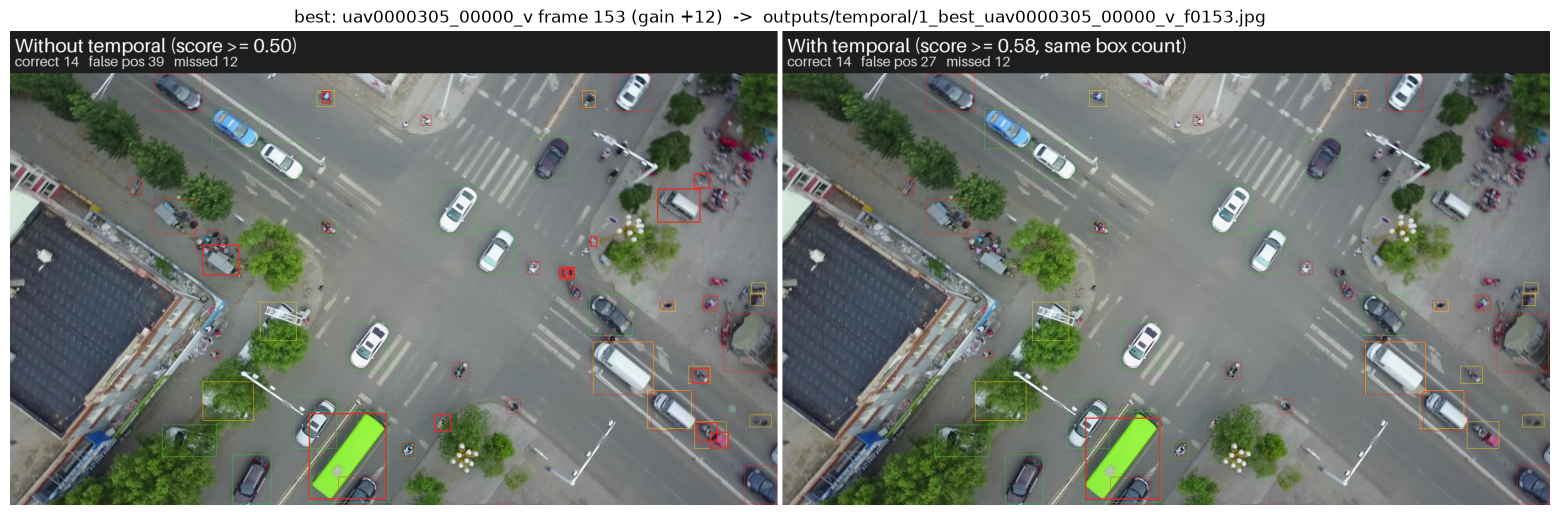

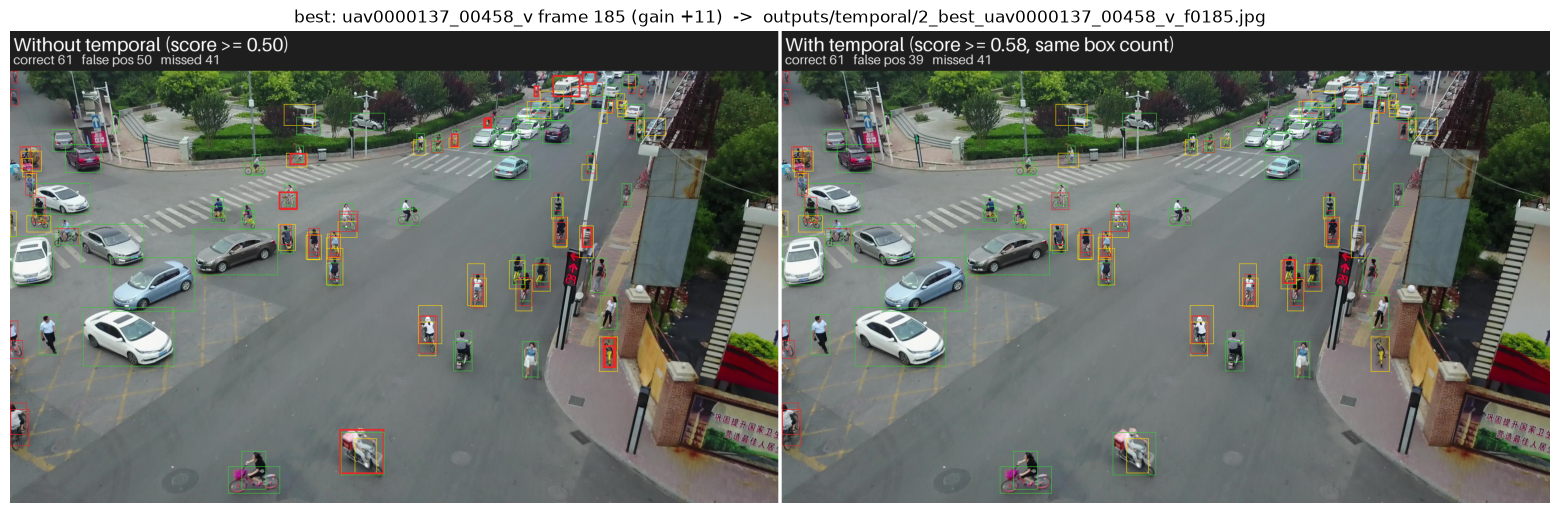

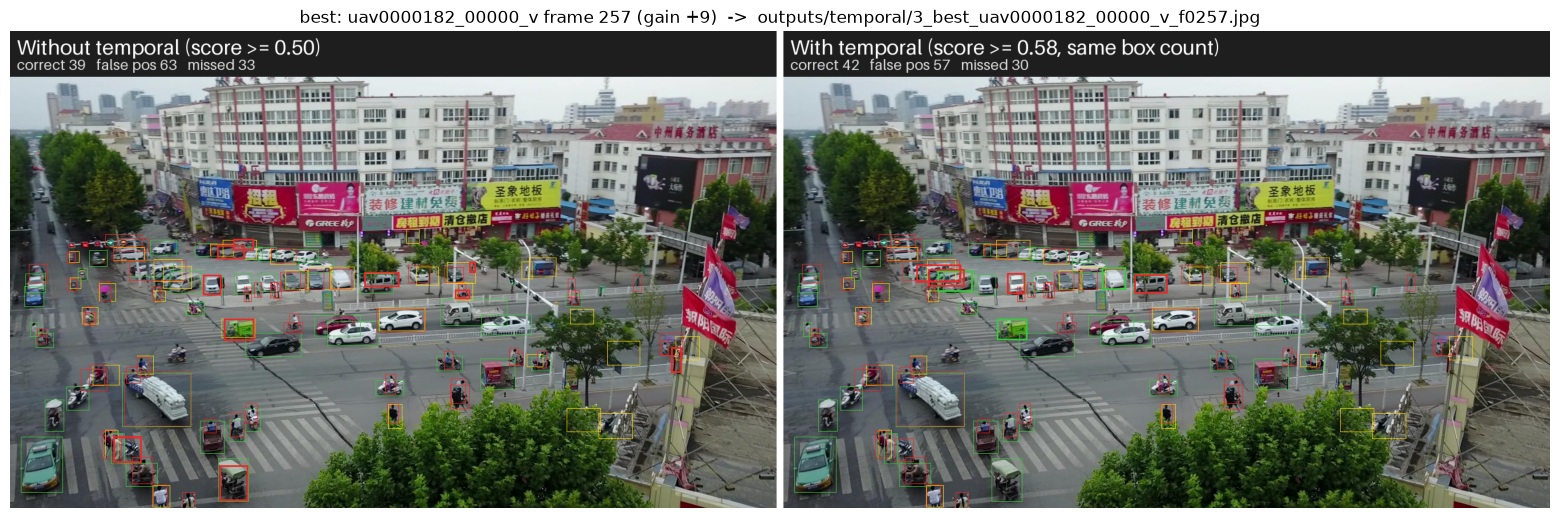

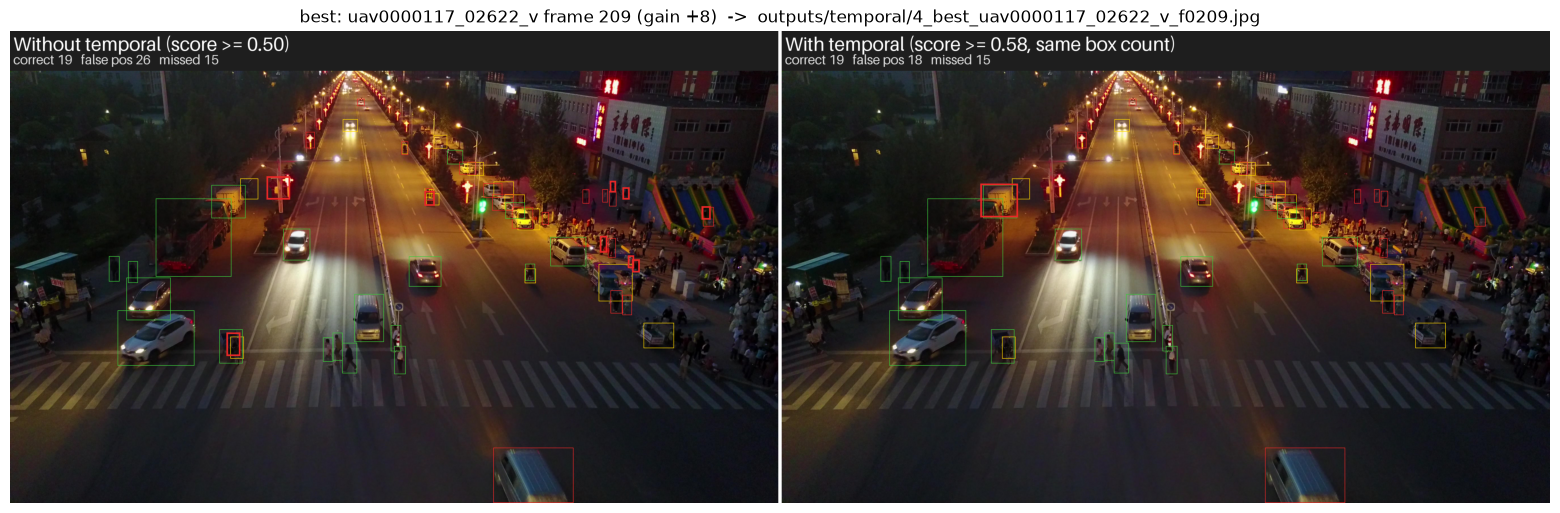

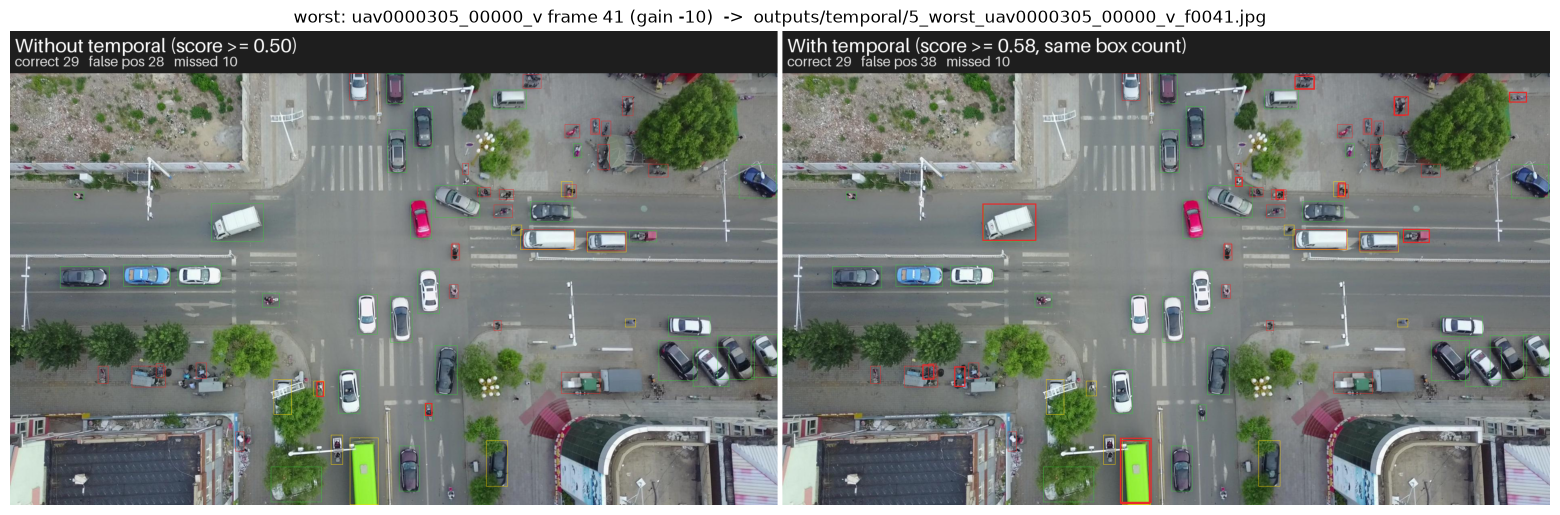

In [7]:
COLOURS = {"tp": (60, 200, 60), "fp": (235, 40, 40), "miss": (255, 215, 0)}


def font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:          # Pillow < 10.1
        return ImageFont.load_default()


def draw_side(img, iid, side, other_status, title):
    ds, status, matched = shown[iid, side]
    im = img.copy()
    draw = ImageDraw.Draw(im)
    lw = max(1, round(im.width / 1300))
    for a, m in zip(gt_boxes[iid], matched):
        if not m:
            x, y, w, h = a["bbox"]
            draw.rectangle([x, y, x + w, y + h], outline=COLOURS["miss"], width=lw)
    for d, s in zip(ds, status):
        if s == "ign":
            continue
        x, y, w, h = d["bbox"]
        thick = other_status.get(d["k"]) != s
        draw.rectangle([x, y, x + w, y + h], outline=COLOURS[s], width=lw * 3 if thick else lw)
    bar_h = int(im.height * 0.08) + 20
    out = Image.new("RGB", (im.width, im.height + bar_h), (30, 30, 30))
    out.paste(im, (0, bar_h))
    d = ImageDraw.Draw(out)
    d.text((12, 6), title, fill="white", font=font(bar_h // 2 - 4))
    d.text((12, bar_h // 2 + 2), f"correct {status.count('tp')}   false pos {status.count('fp')}   missed {matched.count(False)}",
           fill=(220, 220, 220), font=font(bar_h // 3))
    return out


def side_by_side(iid):
    im = images[iid]
    img = Image.open(DATA_ROOT / im["file_name"]).convert("RGB")
    status = {side: {d["k"]: s for d, s in zip(*shown[iid, side][:2])} for side in dets}
    left = draw_side(img, iid, "without", status["with"], f"Without temporal (score >= {THR['without']:.2f})")
    right = draw_side(img, iid, "with", status["without"], f"With temporal (score >= {THR['with']:.2f}, same box count)")
    out = Image.new("RGB", (left.width * 2 + 12, left.height), "white")
    out.paste(left, (0, 0)); out.paste(right, (left.width + 12, 0))
    return out


# Frames: the one with the largest gain in each clip (top 4 clips), plus the frame where rescoring hurts most
picks = frames.sort_values("gain", ascending=False).groupby("clip").head(1).head(4)
picks = pd.concat([picks.assign(kind="best"), frames.sort_values("gain").head(1).assign(kind="worst")])
for n, r in enumerate(picks.itertuples(), 1):
    pic = side_by_side(r.image_id)
    path = OUT_DIR / f"{n}_{r.kind}_{r.clip}_f{r.frame:04d}.jpg"
    pic.save(path, quality=88)
    plt.figure(figsize=(20, 20 * pic.height / pic.width))
    plt.imshow(pic); plt.axis("off")
    plt.title(f"{r.kind}: {r.clip} frame {r.frame} (gain {r.gain:+d})  ->  {path.relative_to(ROOT)}")
    plt.show()

**Observations:** _fill in_